# 12 · Loss experiments, large-image inference, and your capstone

**Prerequisites:** lessons 07–10. **Learning time:** 2–3 hours plus your capstone.

You will compare loss functions on a controlled imbalanced dataset, select a model on validation data, implement overlapping tiles, align test-time augmentations, inspect predictive entropy, and export labels with metadata.

**Success check:** explain what each experiment controls, prove every output pixel receives tile coverage, reverse augmentations before averaging probabilities, and distinguish uncertainty scores from calibrated error probabilities.

These are advanced workflow foundations. Expertise comes from repeated work with real annotation ambiguity, independent datasets, failure analysis, and deployment constraints; toy accuracy does not establish readiness for high-stakes use.


In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "learning" / "data.py").is_file()), None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook inside the complete ImageSegmentationPractical folder.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (10, 3.5), "image.cmap": "gray",
                     "axes.spines.top": False, "axes.spines.right": False})
print("Project:", PROJECT_ROOT.name)


Project: ImageSegmentationPractical


In [2]:
import copy
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from learning.data import make_scene, make_dataset, show_triplet, palette_mask
from learning.torch_models import ArrayDataset, PixelCNN, TinyUNet
from learning.torch_models import run_epoch, confusion_matrix, iou_from_confusion

SEED = 42
FAST_RUN = True  # False increases training; keep True for your first Run All.
torch.manual_seed(SEED)
np.random.seed(SEED)
torch.set_num_threads(2)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("All DataLoaders use num_workers=0 for a simple Windows notebook workflow.")

import json
from PIL import Image


PyTorch: 2.11.0+cu128 | device: cuda
GPU: NVIDIA GeForce RTX 5050 Laptop GPU
All DataLoaders use num_workers=0 for a simple Windows notebook workflow.


## 1. Create a rare class deliberately

We retain normal disks but reduce rectangle regions to small patches. When most pixels are background, a model can achieve high accuracy while missing the rare class. Inspect the class histogram before choosing a loss. The editing below changes the image **and** target together.


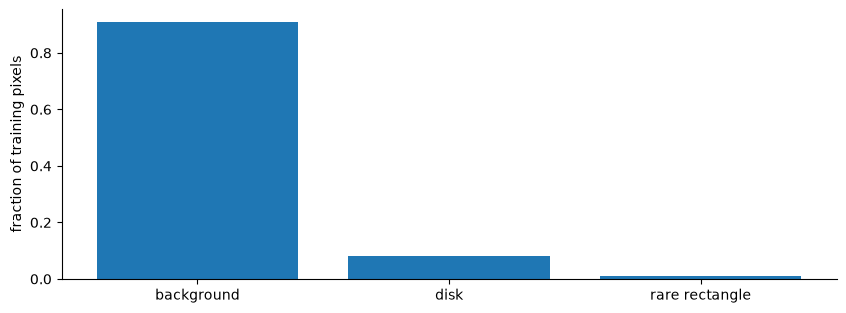

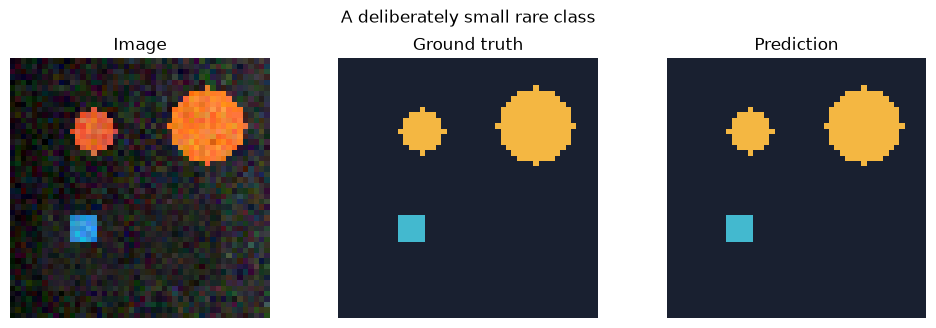

In [3]:
images, masks = make_dataset(n=60 if FAST_RUN else 240, size=48, seed=800)
rng = np.random.default_rng(SEED)
rows, cols = np.mgrid[:48, :48]
for image, mask in zip(images, masks):
    coordinates = np.argwhere(mask == 2)
    center_row, center_col = coordinates[len(coordinates) // 4]
    keep = (abs(rows - center_row) <= 2) & (abs(cols - center_col) <= 2)
    remove = (mask == 2) & ~keep
    image[remove] = np.clip(0.13 + rng.normal(0, 0.04, (int(remove.sum()), 3)), 0, 1)
    mask[remove] = 0
ids = rng.permutation(len(images))
a, b = int(0.6 * len(ids)), int(0.8 * len(ids))
train_ids, val_ids, test_ids = ids[:a], ids[a:b], ids[b:]
assert set(train_ids).isdisjoint(val_ids) and set(train_ids).isdisjoint(test_ids) and set(val_ids).isdisjoint(test_ids)
counts = np.bincount(masks[train_ids].ravel(), minlength=3)
plt.bar(["background", "disk", "rare rectangle"], counts / counts.sum())
plt.ylabel("fraction of training pixels"); plt.show()
show_triplet(images[0], masks[0], masks[0], title="A deliberately small rare class")
plt.show()


## 2. Three loss choices, one prediction task

**Cross-entropy (CE)** rewards correct class probabilities per pixel. **Soft Dice** compares probabilities with one-hot targets, balancing class overlap at the batch level. We combine CE + Dice rather than using a discrete argmax inside a training loss. **Focal loss** multiplies CE by `(1-p_true)^gamma`, reducing easy-pixel contributions.

These implementations assume every pixel is labeled and use three mutually exclusive classes. They include background in soft Dice and have no ignore labels. For partial labels, mask ignored pixels from both numerator and denominator. Loss values from different formulas are not directly comparable; compare a common validation metric.


In [4]:
def soft_dice_loss(logits, target, smooth=1.0):
    probabilities = logits.softmax(dim=1)
    one_hot = F.one_hot(target, num_classes=logits.shape[1]).permute(0, 3, 1, 2).float()
    dims = (0, 2, 3)  # Sum across batch and pixels; keep each class separate.
    intersection = (probabilities * one_hot).sum(dims)
    denominator = probabilities.sum(dims) + one_hot.sum(dims)
    per_class_dice = (2 * intersection + smooth) / (denominator + smooth)
    return 1 - per_class_dice.mean()

def ce_plus_dice(logits, target):
    return F.cross_entropy(logits, target) + soft_dice_loss(logits, target)

def focal_loss(logits, target, gamma=2.0):
    ce = F.cross_entropy(logits, target, reduction="none")
    p_true = torch.exp(-ce)
    return ((1 - p_true).pow(gamma) * ce).mean()

losses = {"CE": F.cross_entropy, "CE + Dice": ce_plus_dice, "Focal gamma=2": focal_loss}
fake_logits = torch.randn(2, 3, 12, 12, requires_grad=True)
fake_target = torch.randint(0, 3, (2, 12, 12))
for name, loss_fn in losses.items():
    loss = loss_fn(fake_logits, fake_target)
    gradient = torch.autograd.grad(loss, fake_logits, retain_graph=True)[0]
    assert torch.isfinite(loss) and torch.isfinite(gradient).all()
    print(name, "loss:", round(loss.item(), 3), "gradient norm:", round(gradient.norm().item(), 4))


CE loss: 1.434 gradient norm: 0.054
CE + Dice loss: 2.111 gradient norm: 0.0656
Focal gamma=2 loss: 0.95 gradient norm: 0.059


## 3. A small controlled ablation

Use identical initialization, split IDs, optimizer settings, batch order, and epoch budget. Change only the loss. Each condition saves its best validation epoch; then choose the condition using validation macro IoU. This is a small single-seed teaching comparison, not evidence that one loss universally wins.

We report standard CE as a shared validation loss even when training uses another objective. Rare-class IoU is also visible because a macro mean can conceal very different class tradeoffs.


In [5]:
train_data = ArrayDataset(images[train_ids], masks[train_ids])
val_loader = DataLoader(ArrayDataset(images[val_ids], masks[val_ids]), batch_size=6, num_workers=0)
test_loader = DataLoader(ArrayDataset(images[test_ids], masks[test_ids]), batch_size=6, num_workers=0)
torch.manual_seed(SEED)
initial_state = copy.deepcopy(PixelCNN(classes=3).state_dict())
results, curves, trained_models = {}, {}, {}
epochs = 10 if FAST_RUN else 50
for name, loss_fn in losses.items():
    torch.manual_seed(SEED)
    model = PixelCNN(classes=3).to(DEVICE); model.load_state_dict(initial_state)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.008)
    train_loader = DataLoader(train_data, batch_size=6, shuffle=True, num_workers=0,
                              generator=torch.Generator().manual_seed(SEED))
    best_score, best_state, curve = -1.0, None, []
    for epoch in range(epochs):
        train_result = run_epoch(model, train_loader, loss_fn, optimizer)
        val_result = run_epoch(model, val_loader, F.cross_entropy)
        curve.append([train_result["loss"], val_result["loss"], val_result["miou"], val_result["iou"][2]])
        if val_result["miou"] > best_score:
            best_score = val_result["miou"]
            best_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state); model.eval()
    results[name] = run_epoch(model, val_loader, F.cross_entropy)
    curves[name], trained_models[name] = np.asarray(curve), model
    print(f"{name:15s} | validation mIoU {results[name]['miou']:.3f} | rare IoU {results[name]['iou'][2]:.3f}")


C:\Users\Hareram ray\AppData\Local\Python\pythoncore-3.13-64\Lib\site-packages\triton\windows_utils.py:465: UserWarning: Failed to find CUDA. Install CUDA Toolkit (https://developer.nvidia.com/cuda-downloads) or set CUDA_HOME / CUDA_PATH environment variable.
  warnings.warn("Failed to find CUDA."


CE              | validation mIoU 0.992 | rare IoU 0.996


CE + Dice       | validation mIoU 0.978 | rare IoU 0.969


Focal gamma=2   | validation mIoU 0.993 | rare IoU 1.000


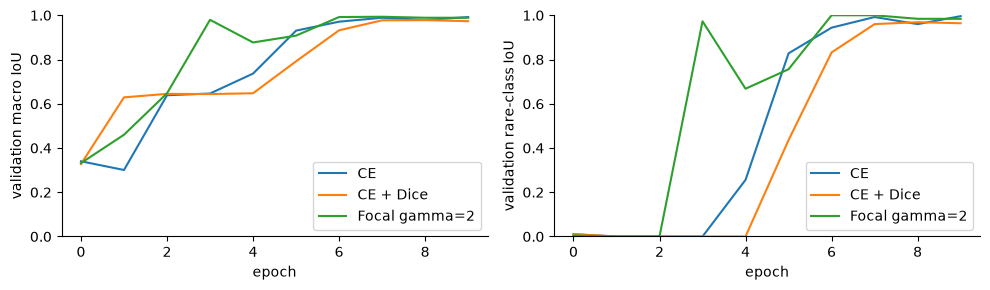

Selected using validation: Focal gamma=2
Untouched test per-class IoU: [0.999 0.982 0.993]
Test mIoU: 0.991


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for name, curve in curves.items():
    axes[0].plot(curve[:, 2], label=name)
    axes[1].plot(curve[:, 3], label=name)
axes[0].set(ylabel="validation macro IoU", xlabel="epoch", ylim=(0, 1))
axes[1].set(ylabel="validation rare-class IoU", xlabel="epoch", ylim=(0, 1))
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()
winner = max(results, key=lambda name: results[name]["miou"])
model = trained_models[winner]
test_result = run_epoch(model, test_loader, F.cross_entropy)
print("Selected using validation:", winner)
print("Untouched test per-class IoU:", test_result["iou"].round(3))
print("Test mIoU:", round(test_result["miou"], 3))


## 4. Predict a large image using overlapping tiles

Tiles limit memory, but convolution padding can cause seams. Average **probabilities** in overlaps with positive weights; do not average class IDs. Every pixel must have nonzero coverage. Here the window gives tile centers more weight, with a positive floor at edges.

Tiling changes available context and may disagree with full-image inference. For context-heavy architectures, use larger tiles or a halo around each tile and keep only the center. This demonstration uses a small CNN and supports images at least as large as the tile.


In [7]:
def tile_starts(length, tile, stride):
    if length < tile or not (0 < stride <= tile):
        raise ValueError("Require length >= tile and 0 < stride <= tile")
    starts = list(range(0, length - tile + 1, stride))
    if starts[-1] != length - tile: starts.append(length - tile)
    return starts

@torch.inference_mode()
def tiled_probabilities(model, image, tile=48, stride=32):
    model.eval()
    if image.ndim != 3 or image.shape[0] != 3:
        raise ValueError("image must be a CHW RGB tensor")
    _, height, width = image.shape
    image = image.to(next(model.parameters()).device)
    starts_y, starts_x = tile_starts(height, tile, stride), tile_starts(width, tile, stride)
    window_1d = torch.hann_window(tile, periodic=False, device=image.device).clamp_min(0.05)
    window = window_1d[:, None] * window_1d[None, :]
    accumulated, coverage = None, torch.zeros(height, width, device=image.device)
    for top in starts_y:
        for left in starts_x:
            crop = image[:, top:top+tile, left:left+tile]
            probabilities = model(crop[None]).softmax(1)[0]
            if accumulated is None:
                accumulated = torch.zeros(probabilities.shape[0], height, width, device=image.device)
            accumulated[:, top:top+tile, left:left+tile] += probabilities * window
            coverage[top:top+tile, left:left+tile] += window
    assert (coverage > 0).all(), "Uncovered pixels would cause invalid division"
    return accumulated / coverage[None], coverage

large_image, large_mask, _ = make_scene(seed=9100, size=113)
large_x = torch.from_numpy(large_image.transpose(2, 0, 1).copy()).to(DEVICE)
tile_p, coverage = tiled_probabilities(model, large_x, tile=48, stride=32)
with torch.inference_mode(): full_p = model(large_x[None]).softmax(1)[0]
assert tile_p.shape == (3, 113, 113)
assert torch.allclose(tile_p.sum(0), torch.ones_like(tile_p[0]), atol=1e-5)
print("minimum coverage:", coverage.min().item())
print("mean |full - tiled| probability difference:", (tile_p-full_p).abs().mean().item())


minimum coverage: 0.002500000176951289
mean |full - tiled| probability difference: 0.0005819478537887335


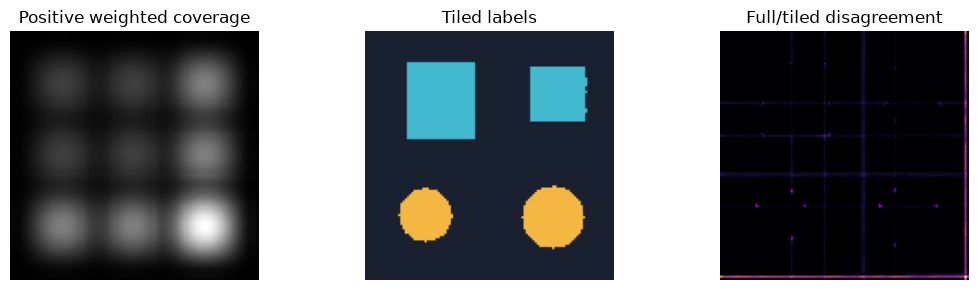

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
axes[0].imshow(coverage.cpu()); axes[0].set_title("Positive weighted coverage")
axes[1].imshow(palette_mask(tile_p.argmax(0).cpu().numpy())); axes[1].set_title("Tiled labels")
axes[2].imshow((tile_p-full_p).abs().mean(0).cpu(), cmap="magma"); axes[2].set_title("Full/tiled disagreement")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()


## 5. Test-time augmentation must undo geometry

Predict the original image and its horizontal reflection. Reflect the second probability map **back** into the original coordinates, then average. Without the inverse transform, corresponding pixels refer to different locations. Test-time augmentation costs extra inference and does not guarantee better accuracy.


pixels changed by TTA: 6


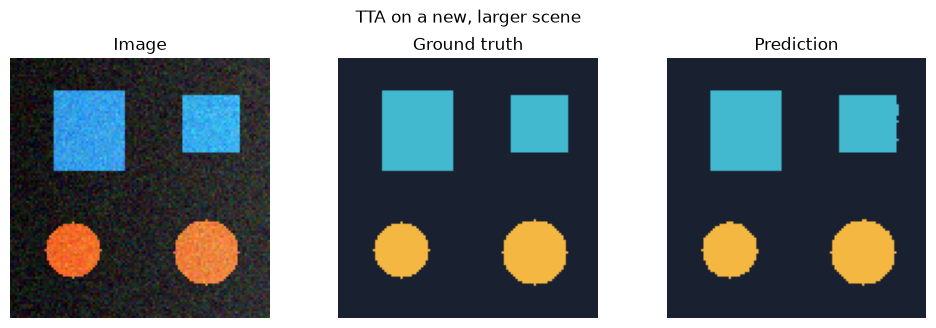

In [9]:
@torch.inference_mode()
def flip_tta_probabilities(model, image_batch):
    model.eval()
    original = model(image_batch).softmax(1)
    flipped_back = model(image_batch.flip(-1)).softmax(1).flip(-1)
    return (original + flipped_back) / 2

tta_p = flip_tta_probabilities(model, large_x[None])[0]
assert tta_p.shape == full_p.shape
print("pixels changed by TTA:", int((tta_p.argmax(0) != full_p.argmax(0)).sum()))
assert torch.equal(large_x.flip(-1).flip(-1), large_x)
show_triplet(large_image, large_mask, tta_p.argmax(0).cpu().numpy(), title="TTA on a new, larger scene")
plt.show()


## 6. Entropy is a signal to investigate

Entropy `-Σ p log(p)` is high when predicted class probabilities are spread out. Divide by `log(K)` to scale it to `[0,1]` for K classes. It measures uncertainty in this model's output distribution; it is **not** the probability that a prediction is wrong.

Neural networks can be confidently wrong under a color/domain shift. Compare uncertainty with actual errors where labels exist, and use reliability/calibration analysis on independent validation data before interpreting probabilities operationally.


ordinary scene error fraction: 0.002 mean entropy: 0.159
color-shift error fraction: 0.22 mean entropy: 0.195


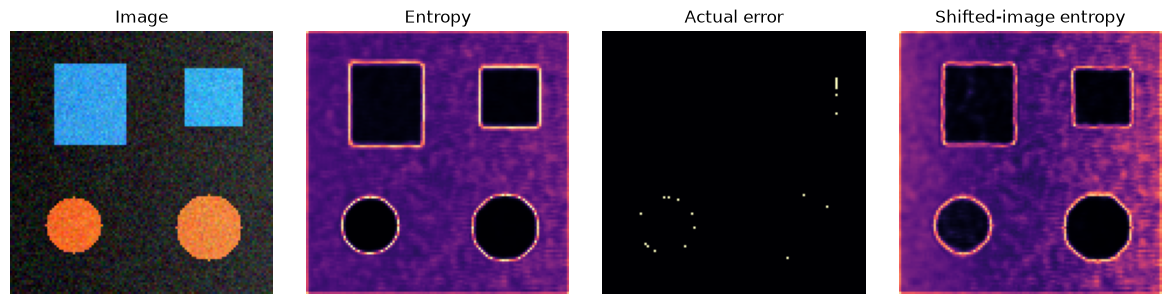

In [10]:
def normalized_entropy(probabilities):
    safe = probabilities.clamp_min(1e-8)
    return -(safe * safe.log()).sum(0) / np.log(probabilities.shape[0])

entropy = normalized_entropy(tta_p).cpu().numpy()
prediction = tta_p.argmax(0).cpu().numpy()
errors = prediction != large_mask
shift_image, shift_mask, _ = make_scene(seed=9100, size=113, shift=True)
shift_x = torch.from_numpy(shift_image.transpose(2, 0, 1).copy())[None].to(DEVICE)
with torch.inference_mode(): shift_p = flip_tta_probabilities(model, shift_x)[0]
shift_prediction = shift_p.argmax(0).cpu().numpy()
shift_entropy = normalized_entropy(shift_p).cpu().numpy()
print("ordinary scene error fraction:", errors.mean().round(3), "mean entropy:", entropy.mean().round(3))
print("color-shift error fraction:", (shift_prediction != shift_mask).mean().round(3), "mean entropy:", shift_entropy.mean().round(3))
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, value, title in zip(axes, [large_image, entropy, errors, shift_entropy],
                           ["Image", "Entropy", "Actual error", "Shifted-image entropy"]):
    ax.imshow(value, cmap="magma"); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()


## 7. Export raw labels and a complete inference contract

Save class IDs in a lossless PNG and colors in a separate preview. Export preprocessing, class names, architecture, and selection information alongside the weights. These files are local learning artifacts; production serving also needs latency/memory measurement, input validation, monitoring, and a versioned evaluation process.


In [11]:
output_dir = PROJECT_ROOT / "artifacts" / "12_capstone"
output_dir.mkdir(parents=True, exist_ok=True)
label_path = output_dir / "prediction_ids.png"
preview_path = output_dir / "prediction_preview.png"
Image.fromarray(prediction.astype(np.uint8)).save(label_path)
Image.fromarray(palette_mask(prediction)).save(preview_path)
roundtrip = np.asarray(Image.open(label_path))
assert np.array_equal(roundtrip, prediction)
metadata = {
    "architecture": "PixelCNN", "width": 12,
    "classes": ["background", "disk", "rectangle"],
    "layout": "NCHW RGB", "input_range": [0.0, 1.0],
    "normalization": "divide uint8 RGB by 255; no further normalization",
    "selected_loss": winner, "selection": "best validation macro IoU",
    "seed": SEED, "test_miou_single_pass": float(test_result["miou"]),
    "test_protocol": "single forward pass; global confusion matrix; macro IoU over present classes",
    "torch_version": str(torch.__version__), "inference": "horizontal flip TTA; argmax",
    "label_format": "uint8 PNG; IDs 0,1,2", "training_data": "synthetic rare-class demo",
}
(output_dir / "metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
torch.save({"state_dict": {k: v.detach().cpu() for k, v in model.state_dict().items()},
            "metadata": metadata}, output_dir / "model.pt")
saved = torch.load(output_dir / "model.pt", map_location=DEVICE, weights_only=True)
restored = PixelCNN(classes=len(saved["metadata"]["classes"]), width=saved["metadata"]["width"]).to(DEVICE)
restored.load_state_dict(saved["state_dict"]); restored.eval()
with torch.inference_mode():
    torch.testing.assert_close(restored(large_x[None]), model(large_x[None]))
print("Exported labels, preview, metadata and reload-verified weights to", output_dir)


Exported labels, preview, metadata and reload-verified weights to C:\Users\Hareram ray\AI\ImageSegmentationPractical\artifacts\12_capstone


## 8. Measure inference latency with a clear scope

GPU kernels launch asynchronously. Synchronize before and after the timed region so the clock measures completed work. Warm up first, report repeated timings, and state what the timing includes.

This measures one resident `113×113` tensor through the model. It excludes image decoding, host-to-device transfer, preprocessing, TTA, tiling, and file export. Full application latency needs those stages measured too; a tiny synthetic input is not a deployment benchmark.


In [12]:
from time import perf_counter

def synchronize_device():
    if DEVICE.type == "cuda": torch.cuda.synchronize(DEVICE)

model.eval()
timings_ms = []
with torch.inference_mode():
    for _ in range(3): _ = model(large_x[None])
    synchronize_device()
    for _ in range(10):
        synchronize_device()
        start = perf_counter()
        _ = model(large_x[None])
        synchronize_device()
        timings_ms.append((perf_counter() - start) * 1000)
print("Model-only latency, input already on", DEVICE)
print("median ms:", round(float(np.median(timings_ms)), 3),
      "p90 ms:", round(float(np.percentile(timings_ms, 90)), 3))


Model-only latency, input already on cuda
median ms: 0.198 p90 ms: 0.354


## Experiment 1 · Which loss helps the rare class?

Change the rare patch radius from 2 to 1, then repeat the controlled ablation. Record background, disk, and rectangle IoU. Repeat at least three seeds before favoring a loss. Do not compare the numerical magnitude of focal loss with CE as if they measured the same quantity.

<details><summary>Worked solution 1</summary>

Edit the `keep` expression, regenerate the data, and rerun all dependent cells. Keep model initialization and batch order identical across conditions **within each seed**. Report the mean and spread of validation rare-class IoU. A loss can improve macro IoU while harming boundary quality; inspect errors and consider a boundary metric from lesson 06. The short optimization budget can influence the ranking.
</details>


## Experiment 2 · Deliberately break tiling or TTA

Try `stride=60` with `tile=48`: why must it fail? Then remove the final `.flip(-1)` in the TTA function and inspect the averaged map. Restore the correct code afterward.

<details><summary>Worked solution 2</summary>

Stride larger than the tile can leave unvisited gaps; our argument check rejects it. The last tile start must also reach the far edge when image dimensions are not multiples of the stride. Without inverse flipping, left-side class probabilities are averaged with unrelated right-side predictions, blurring or duplicating objects. Probability sums can still equal one, so that check alone cannot detect misalignment.
</details>


## Experiment 3 · Investigate confident mistakes

Find pixels where `shift_prediction != shift_mask` but `shift_entropy < 0.2`. Count and visualize them. What would an entropy threshold miss?

<details><summary>Worked solution 3</summary>

Use `confident_errors = (shift_prediction != shift_mask) & (shift_entropy < 0.2)` and display it over the shifted image. A low-entropy incorrect answer is a confident error. An uncertainty-only review rule will miss it. Broader out-of-distribution evaluation, calibration checks, diverse training data, and human review criteria address different parts of this problem; none is established by this toy experiment.
</details>


Confidently wrong shifted pixels: 2511


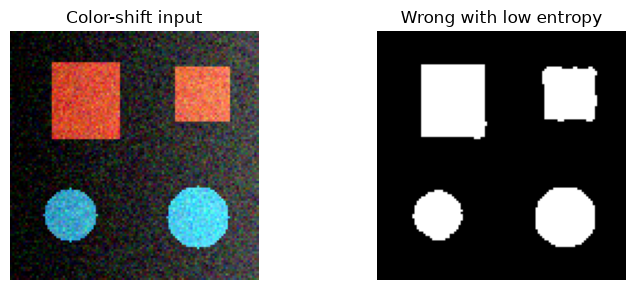

In [13]:
confident_errors = (shift_prediction != shift_mask) & (shift_entropy < 0.2)
print("Confidently wrong shifted pixels:", int(confident_errors.sum()))
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].imshow(shift_image); axes[0].set_title("Color-shift input")
axes[1].imshow(confident_errors, vmin=0, vmax=1); axes[1].set_title("Wrong with low entropy")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()


## Capstone · Replace the toy data with a real question

Choose a manageable labeled dataset, such as the optional pet dataset from lesson 10, or your own carefully annotated images. Define classes, ignore regions, unit of splitting, and intended use before training.

| Deliverable | Evidence required | Points |
|---|---|---:|
| Data audit | Pair checks, label histogram, ten overlays, annotation rules | 20 |
| Honest evaluation | Group-aware train/validation/test split and leakage checks | 20 |
| Baselines | Simple baseline plus learned baseline on identical splits | 15 |
| Controlled improvement | One-factor ablation, fixed budget, three seeds if practical | 15 |
| Error analysis | Per-class IoU/Dice, small-object and boundary failures, shift examples | 15 |
| Reproducible artifact | Reload-equal predictions, class metadata, raw-mask export | 15 |

Aim for **80/100 with no missing data-audit or split checks** before calling the project complete. Add your conclusions in Markdown cells: what failed, why you think it failed, and what evidence would change your mind. This rubric evaluates a learning project; deployment needs its own acceptance criteria.


## Checkpoint and common errors

- Explain why soft Dice uses probabilities but CE takes logits.
- Average probability maps, not numeric class IDs.
- Verify tile coverage and original-coordinate alignment independently.
- Keep test data out of hyperparameter and model selection.
- An all-ignored batch needs explicit handling; the toy loss implementations assume none.
- Reload on CPU or GPU using `map_location`; persist preprocessing alongside weights.
- Record limitations and next experiments instead of calling a toy model “expert-level.”

## References and further study

- [Focal Loss paper](https://arxiv.org/abs/1708.02002)
- [V-Net paper: Dice-based optimization](https://arxiv.org/abs/1606.04797)
- [Calibration of modern neural networks](https://arxiv.org/abs/1706.04599)
- [PyTorch inference_mode](https://docs.pytorch.org/docs/stable/generated/torch.autograd.grad_mode.inference_mode.html)

For a further project, study panoptic segmentation, promptable foundation models, active learning, or domain adaptation. Start with a precise problem and an evaluation plan, then choose the architecture.
